# 04 – Agréger les sources et créer les features

## Leçon 1 – Où calculer les features ?

On a trois sources :
- `table_med.parquet` : commune × jour, 12,8 millions de lignes, la cible `feu` ;
- `meteo_points_med.parquet` : **point SAFRAN** × jour, 1995-2025, 13,8 millions de lignes ;
- `communes_med.csv` : chaque commune, son point SAFRAN, sa population.

Dans le projet 13, on calculait les fenêtres glissantes (pluie sur 30 jours…) **par commune**. Ici, 3 505 communes se partagent 1 215 points météo : deux communes rattachées au même point ont **exactement** la même météo. Calculer par commune ferait donc 3 fois le même travail.

👉 **Règle d'or du traitement de gros volumes : calculer au niveau le plus agrégé possible, puis joindre.**

1. features **météo** → calculées **par point** ;
2. features **historique de feux** → calculées **par commune** (elles dépendent de la commune) ;
3. features **fixes** (population, position) → simple jointure.

C'est le même réflexe qu'en demand planning : on calcule la saisonnalité par famille de produits, pas par référence.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

meteo = pd.read_parquet("../data/processed/meteo_points_med.parquet")
communes = pd.read_csv("../data/processed/communes_med.csv", dtype={"code": str, "dept": str})
table = pd.read_parquet("../data/processed/table_med.parquet")

print(meteo.shape, communes.shape, table.shape)

(13757445, 10) (3505, 11) (12803765, 3)


## Étape 1 – Un identifiant simple pour chaque point

Un point est repéré par deux colonnes (`LAMBX`, `LAMBY`). C'est plus simple avec un seul numéro : `ngroup()` numérote les groupes 0, 1, 2…

In [2]:
meteo["point"] = meteo.groupby(["LAMBX", "LAMBY"]).ngroup()
cle_points = meteo[["LAMBX", "LAMBY", "point"]].drop_duplicates()
communes = communes.merge(cle_points, on=["LAMBX", "LAMBY"], how="left")

meteo = meteo.drop(columns=["LAMBX", "LAMBY"]).sort_values(["point", "jour"]).reset_index(drop=True)
print(meteo["point"].nunique(), "points ;", communes["point"].isna().sum(), "commune sans point")   # 1215 ; 0

1215 points ; 0 commune sans point


## Étape 2 – Les fenêtres glissantes, par point

Exactement la même logique que dans le projet 13 (`rolling` sur chaque groupe), avec les variables SIM2 :

| Feature | Calcul | Intuition |
|---|---|---|
| `pluie_7j`, `pluie_30j` | somme glissante | la végétation a-t-elle reçu de l'eau récemment ? |
| `evapo_30j` | somme glissante de l'ETP | combien d'eau l'air a « aspiré » |
| `bilan_hydrique_30j` | pluie_30j − evapo_30j | négatif = déficit d'eau |
| `temp_max_7j` | moyenne glissante | une vague de chaleur dure plusieurs jours |
| `humidite_sol_7j` | moyenne glissante du SWI | tendance de l'humidité des sols |
| `jours_sans_pluie` | astuce cumsum / cumcount | durée de la sécheresse en cours |
| `vent_fort` | vent moyen ≥ 30 km/h | ≈ 2 % des jours : mistral, tramontane |

⏱️ On mesure le temps avec `time.time()` : avec des millions de lignes, on surveille ce qui est lent.

In [3]:
debut = time.time()
par_point = meteo.groupby("point")

meteo["pluie_7j"]  = par_point["pluie"].transform(lambda s: s.rolling(7,  min_periods=1).sum())
meteo["pluie_30j"] = par_point["pluie"].transform(lambda s: s.rolling(30, min_periods=1).sum())
meteo["evapo_30j"] = par_point["evapo"].transform(lambda s: s.rolling(30, min_periods=1).sum())
meteo["temp_max_7j"] = par_point["temp_max"].transform(lambda s: s.rolling(7, min_periods=1).mean())
meteo["humidite_sol_7j"] = par_point["humidite_sol"].transform(lambda s: s.rolling(7, min_periods=1).mean())
meteo["bilan_hydrique_30j"] = meteo["pluie_30j"] - meteo["evapo_30j"]

# jours sans pluie : on numérote les « blocs » qui commencent à chaque jour de pluie
jour_de_pluie = (meteo["pluie"] >= 1).astype(int)
meteo["bloc"] = jour_de_pluie.groupby(meteo["point"]).cumsum()
meteo["jours_sans_pluie"] = meteo.groupby(["point", "bloc"]).cumcount()
meteo = meteo.drop(columns="bloc")

meteo["vent_fort"] = (meteo["vent_moy"] >= 30).astype("int8")

print(f"{time.time() - debut:.0f} s")
print(f"part de jours de vent fort : {meteo['vent_fort'].mean():.1%}")

10 s
part de jours de vent fort : 1.6%


**Pourquoi commencer en 1995 ?** Le 1ᵉʳ janvier 1996, `pluie_30j` contient bien les 30 vrais jours précédents (décembre 1995). Sans cette année de « préchauffage », les premières semaines auraient des fenêtres incomplètes. Pareil pour 2016 : ses fenêtres utilisent la fin de 2015.

On sauvegarde les features météo **par point pour 1996-2025** : elles serviront aux scénarios 2027 (notebook 08). Puis on ne garde que **2016-2025** pour la table d'apprentissage (les années où l'on connaît les feux) :

In [4]:
meteo_scenarios = meteo[meteo["jour"] >= "1996-01-01"].merge(cle_points, on="point")
meteo_scenarios.to_parquet("../data/processed/meteo_features_points_med.parquet", index=False)
print("pour les scénarios :", meteo_scenarios.shape)
del meteo_scenarios   # on libère la mémoire

meteo = meteo[meteo["jour"] >= "2016-01-01"]
print("pour l'apprentissage :", meteo.shape)   # attendu : (4438395, 18) = 1 215 points × 3 653 jours

pour les scénarios : (13313970, 19)


pour l'apprentissage : (4438395, 17)


## Étape 3 – La grande jointure

Chaque ligne commune × jour va chercher la météo de **son** point ce jour-là :
1. on ajoute à la table le numéro de point de chaque commune (petite jointure sur `code`) ;
2. on joint la météo sur (`point`, `jour`).

**Astuce mémoire :** les colonnes météo sont en `float64` (8 octets par nombre). Une précision de 7 chiffres (`float32`, 4 octets) suffit largement pour des mm de pluie ou des °C → mémoire divisée par 2.

In [5]:
colonnes_meteo = [c for c in meteo.columns if c not in ["point", "jour", "vent_fort", "jours_sans_pluie"]]
meteo[colonnes_meteo] = meteo[colonnes_meteo].astype("float32")
meteo["jours_sans_pluie"] = meteo["jours_sans_pluie"].astype("int16")

infos = communes[["code", "dept", "point", "lat", "lon", "population", "densite"]].copy()
infos["code"] = infos["code"].astype(table["code"].dtype)   # même type category que la table

df = table.merge(infos, on="code", how="left")
df = df.merge(meteo, on=["point", "jour"], how="left")

print(df.shape)
print("valeurs manquantes :", df[colonnes_meteo].isna().sum().sum())   # attendu : 0
print(f"mémoire : {df.memory_usage(deep=True).sum() / 1e9:.1f} Go")

(12803765, 24)


valeurs manquantes : 0
mémoire : 1.5 Go


## Étape 4 – Le calendrier

In [6]:
df["mois"] = df["jour"].dt.month.astype("int8")
df["jour_annee"] = df["jour"].dt.day_of_year.astype("int16")
df["jour_semaine"] = df["jour"].dt.day_of_week.astype("int8")
df["week_end"] = (df["jour_semaine"] >= 5).astype("int8")

## Étape 5 – L'historique de feux (sans fuite d'information !)

Rappel essentiel du projet 13 : pour prédire le jour J, on n'a le droit qu'aux informations connues **la veille**. D'où le `shift(1)` : on décale d'un jour avant de compter.

| Feature | Calcul |
|---|---|
| `feux_commune_365j` | jours avec feu dans la commune sur les 365 jours précédents |
| `feux_commune_cumul` | jours avec feu dans la commune depuis 2016 (jusqu'à la veille) |
| `feux_dept_veille` | communes du **même département** avec un feu la veille |
| `feux_zone_veille` | communes de **toute la zone** avec un feu la veille |

Nouveau : on a maintenant 15 départements, donc deux échelles de « contagion » (même département / toute la zone). Les jours de crise (2017, 2022), les feux s'enchaînent partout.

In [7]:
debut = time.time()
df = df.sort_values(["code", "jour"]).reset_index(drop=True)
par_commune = df.groupby("code", observed=True)["feu"]

df["feux_commune_365j"] = par_commune.transform(lambda s: s.shift(1).rolling(365, min_periods=1).sum()).fillna(0).astype("float32")
df["feux_commune_cumul"] = par_commune.transform(lambda s: s.shift(1).cumsum()).fillna(0).astype("float32")

feux_dept_jour = df.groupby(["dept", "jour"])["feu"].sum()
veille_dept = feux_dept_jour.groupby(level="dept").shift(1).fillna(0).rename("feux_dept_veille")
df = df.merge(veille_dept, left_on=["dept", "jour"], right_index=True, how="left")

feux_zone_jour = df.groupby("jour")["feu"].sum()
df = df.merge(feux_zone_jour.shift(1).fillna(0).rename("feux_zone_veille"), left_on="jour", right_index=True, how="left")

print(f"{time.time() - debut:.0f} s")

9 s


**Vérification anti-fuite** sur Martigues (13056), qui a eu des feux les 7, 9 et 11 juillet 2016 : le compteur doit augmenter **le lendemain** de chaque feu, pas le jour même (attendu : 4 → 5 le 8, 5 → 6 le 10, 6 → 7 le 12).

In [8]:
martigues = df[(df["code"] == "13056") & (df["jour"].between("2016-07-07", "2016-07-12"))]
martigues[["jour", "feu", "feux_commune_cumul", "feux_commune_365j"]]

,jour,feu,feux_commune_cumul,feux_commune_365j
4917126,2016-07-07,1,4.0,4.0
4917127,2016-07-08,0,5.0,5.0
4917128,2016-07-09,1,5.0,5.0
4917129,2016-07-10,0,6.0,6.0
4917130,2016-07-11,1,6.0,6.0
4917131,2016-07-12,0,7.0,7.0


## Leçon 2 – Attention aux compteurs qui grossissent avec le temps

`feux_commune_cumul` compte les feux **depuis 2016**. Pour Martigues, il vaut ≈ 20 fin 2016, ≈ 100 fin 2020, ≈ 180 fin 2025. Problème : le modèle apprend sur 2016-2020, puis on l'utilise sur 2023-2025, avec des valeurs qu'il **n'a jamais vues**. Un modèle à base d'arbres ne sait pas **extrapoler** : au-delà de la plus grande valeur vue, il répond comme pour cette valeur.

C'est un cas de **dérive** (*data drift*) : la distribution d'une variable change entre l'entraînement et l'utilisation. En demand planning, c'est comme utiliser les « ventes cumulées depuis le lancement » pour prédire : la variable grandit mécaniquement, même si le produit ne se vend pas mieux.

**Solution :** transformer le compteur en **taux** (feux ÷ jours écoulés), qui reste comparable dans le temps. On ajoute un petit « a priori » (365 jours fictifs à 0,1 % de feu), comme le lissage de la baseline : en janvier 2016, on n'a aucun historique, donc le taux part de 0,1 % au lieu de 0/0.

In [9]:
jours_ecoules = (df["jour"] - pd.Timestamp("2016-01-01")).dt.days
df["taux_feu_commune"] = ((df["feux_commune_cumul"] + 365 * 0.001) / (jours_ecoules + 365)).astype("float32")

df[df["code"] == "13056"].iloc[[0, 365, 1826, 3652]][["jour", "feux_commune_cumul", "taux_feu_commune"]]

,jour,feux_commune_cumul,taux_feu_commune
4916938,2016-01-01,0.0,0.001000
4917303,2016-12-31,26.0,0.036116
4918764,2020-12-31,85.0,0.038962
4920590,2025-12-31,183.0,0.045647


**Lecture :** le cumul de Martigues ne fait que grimper, alors que son taux se stabilise vers ≈ 5 % des jours. C'est ce taux qu'on donnera au modèle.

## Étape 6 – Une variable « présence humaine »

Les feux sont allumés par des humains (malveillance, imprudences) : plus il y a de monde, plus il y a d'étincelles potentielles. Mais une ville très dense (centre de Nice) a peu de végétation à brûler…

La densité va de 0,2 à plus de 5 000 habitants/km² : une échelle très étirée. On en prend le **logarithme** (`np.log1p` = log(1 + x)) pour la « tasser » : 10 → 2,4 ; 100 → 4,6 ; 1 000 → 6,9. Pour un modèle à base d'arbres ça ne change rien, mais ça rend les graphiques lisibles.

In [10]:
df["log_densite"] = np.log1p(df["densite"]).astype("float32")
df["population"] = df["population"].astype("float32")
df = df.drop(columns=["densite", "point"])

## Étape 7 – Regarder les relations avec la cible

Comme dans le projet 13 : on découpe une feature en tranches (`pd.cut`) et on calcule le **taux de feu** de chaque tranche.

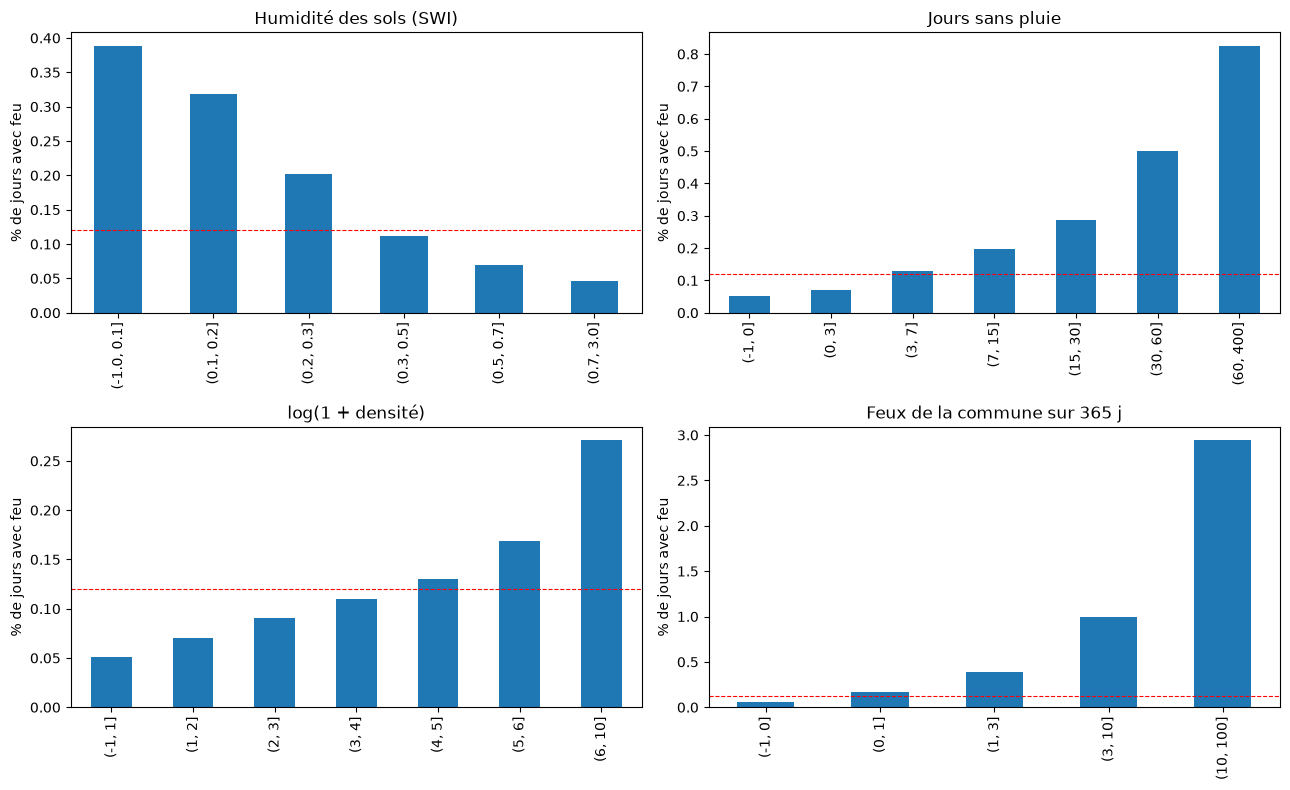

In [11]:
taux_moyen = df["feu"].mean() * 100
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

graphiques = [
    ("humidite_sol", [-1, 0.1, 0.2, 0.3, 0.5, 0.7, 3], "Humidité des sols (SWI)"),
    ("jours_sans_pluie", [-1, 0, 3, 7, 15, 30, 60, 400], "Jours sans pluie"),
    ("log_densite", [-1, 1, 2, 3, 4, 5, 6, 10], "log(1 + densité)"),
    ("feux_commune_365j", [-1, 0, 1, 3, 10, 100], "Feux de la commune sur 365 j"),
]
for ax, (col, bornes, titre) in zip(axes.flat, graphiques):
    tranches = pd.cut(df[col], bins=bornes)
    (df.groupby(tranches, observed=True)["feu"].mean() * 100).plot(kind="bar", ax=ax, title=titre)
    ax.axhline(taux_moyen, color="red", linestyle="--", linewidth=0.8)
    ax.set_ylabel("% de jours avec feu")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

Pointillé rouge = taux moyen (0,12 %).

**Lecture :**
- **Humidité des sols** : relation parfaitement régulière. Sol très sec (SWI ≤ 0,1) → **0,39 %** de jours avec feu ; sol humide (> 0,7) → 0,05 %. Soit **×8** entre les deux. C'est la grande nouveauté de SIM2.
- **Jours sans pluie** : le risque grimpe sans plateau, de 0,05 % (il a plu) à **0,82 %** au-delà de 60 jours. Dans le projet 13, la courbe était irrégulière (trop peu de données) ; avec 15 départements, elle devient lisse.
- **Densité** : le risque **augmente** avec la présence humaine, jusqu'aux communes les plus denses (0,27 %, ×5 par rapport aux villages quasi déserts). Les humains allument les feux !
- **Historique** : une commune qui a eu plus de 10 jours de feu dans l'année écoulée a **3 %** de risque chaque jour, ×25 la moyenne. C'est la variable la plus « forte », comme dans le projet 13.

## Étape 8 – Sauvegarde

In [12]:
df["code"] = df["code"].astype(str)
df["dept"] = df["dept"].astype("category")
df.to_parquet("../data/processed/features_med.parquet", index=False)

import os
print(df.shape)
print(f"{os.path.getsize('../data/processed/features_med.parquet') / 1e6:.0f} Mo sur disque")
df.columns.tolist()

(12803765, 32)
271 Mo sur disque


['code',
 'jour',
 'feu',
 'dept',
 'lat',
 'lon',
 'population',
 'pluie',
 'temp_moy',
 'temp_max',
 'vent_moy',
 'humidite_moy',
 'evapo',
 'humidite_sol',
 'pluie_7j',
 'pluie_30j',
 'evapo_30j',
 'temp_max_7j',
 'humidite_sol_7j',
 'bilan_hydrique_30j',
 'jours_sans_pluie',
 'vent_fort',
 'mois',
 'jour_annee',
 'jour_semaine',
 'week_end',
 'feux_commune_365j',
 'feux_commune_cumul',
 'feux_dept_veille',
 'feux_zone_veille',
 'taux_feu_commune',
 'log_densite']

## 🎯 À toi de jouer

1. Trace le taux de feu selon `vent_fort` (0 / 1). Le vent fort augmente-t-il le risque ?
2. Même chose avec `week_end`. Y a-t-il plus de feux le week-end ?

In [13]:
# à toi

<details><summary>Correction</summary>

```python
df.groupby("vent_fort")["feu"].mean() * 100
df.groupby("week_end")["feu"].mean() * 100
```
Compare au taux moyen de 0,12 %. Attention : un vent fort est souvent associé à de la pluie en hiver (tempêtes) **et** à la sécheresse en été (mistral) ; l'effet moyen peut donc être trompeur. Le modèle saura croiser vent et saison.
</details>

## Récap

1. **Calculer au niveau le plus agrégé** (point météo), puis joindre → 3 fois moins de calculs.
2. **Préchauffage** : l'année 2015 sert juste à remplir les fenêtres glissantes du début 2016.
3. `float32`, `int8`, `category` : diviser la mémoire par 2 ou plus sans perte utile.
4. Historique de feux **décalé d'un jour** (`shift(1)`) à trois échelles : commune, département, zone, et un **taux** historique plutôt qu'un compteur qui dérive.
5. Nouvelles variables : **humidité des sols** et **densité de population**.

**Prochaine étape (05) :** la baseline à battre.